**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**02 | Signal Preprocessing: Windowing and Quality Controls**

![Stage 02 scientific workflow](../images/02_workflow.svg)

**Objective:** Segment continuous HARTH accelerometer recordings into two-second, label-pure windows, excluding candidates that cross activity changes or timestamp discontinuities.

**Dataset:** The pinned HARTH v2.0 recording `S023.csv`, with lower-back and thigh acceleration sampled at 50 Hz.

**Notebook Scope:** Generate windows for one participant, inspect retained activity support and signal segments, and verify window integrity. No fitted scaling, model training or subject-independent evaluation is performed.

**01. Imports and Environment**

In [1]:
# ======================== 01. Imports and Environment ========================

# ------ 1. Import standard-library tools for portable repository paths. ------
import sys
from pathlib import Path

# ------- 2. Import data analysis, figures and notebook display tools. --------
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# --------- 3. Resolve the project root without a fixed local drive. ----------
root = Path.cwd().resolve()
while not (root / "code/python/src/core/data_loading.py").is_file():
    if root.parent == root:
        raise RuntimeError("Open the notebook inside the repository.")
    root = root.parent

# --------- 4. Register the two existing project module directories. ----------
sys.path.insert(0, str(root / "code/python/src"))
sys.path.insert(0, str(root / "studies/wearable_activity_recognition/src"))

# ------- 5. Reuse source inspection, windowing and plotting utilities. -------
from core.data_inspection import inspect_data, plot_signal
from core.signal_preprocessing import create_signal_windows
from harth_data import ACTIVITY_NAMES, ensure_harth_sample, load_harth_subject

# -------- 6. Confirm the selected repository and windowing function. --------
print("Repository:", root)
print("Windowing function:", create_signal_windows.__name__)

Repository: D:\human-movement-intelligence
Windowing function: create_signal_windows


**02. Load the Original HARTH Recording**

The source file is retrieved from the pinned public release or reused from the local Git-ignored cache.

In [ ]:
# ===================== 02. Load Original HARTH Recording =====================

# ------ 1. Select the ignored cache for the original HARTH source file. ------
data_dir = root / "data" / "raw" / "harth_v2"

# ------ 2. Reuse or retrieve S023 without altering its source samples. -------
file_path = ensure_harth_sample(data_dir, subject="S023")
data, channels = load_harth_subject(file_path)

# --------- 3. Inspect the continuous recording before segmentation. ----------
inspect_data(data, name="HARTH S023: continuous input")

# -------- 4. Report participant identity and observed source labels. ---------
print("Participant:", file_path.stem)
print("Recorded activity classes:", sorted(data["label"].unique().tolist()))

Using cached HARTH data: D:\human-movement-intelligence\data\raw\harth_v2\S023.csv
HARTH subject S023: 137,646 rows, 6 sensors

===== HARTH S023: continuous input =====
Rows: 137646 | Columns: 8
Missing values: 0
Columns: timestamp, back_x, back_y, back_z, thigh_x, thigh_y, thigh_z, label
              timestamp    back_x    back_y    back_z   thigh_x   thigh_y   thigh_z  label
2019-01-12 00:00:00.000 -1.108887  0.057861 -0.076904 -1.396973 -0.327148 -0.141846      6
2019-01-12 00:00:00.020 -1.054932  0.073486 -0.113770 -1.363281 -0.386475 -0.321533      6
2019-01-12 00:00:00.040 -0.911377 -0.007568 -0.160156 -1.080078 -0.096680 -0.354492      6
2019-01-12 00:00:00.060 -0.865234 -0.062500 -0.176025 -1.012939  0.163574 -0.229736      6
2019-01-12 00:00:00.080 -0.992920 -0.026123 -0.178467 -0.989014  0.199951 -0.088379      6
Participant: S023
Recorded activity classes: [1, 2, 3, 4, 5, 6, 7, 8]


**03. Define the Windowing Protocol**

At 50 Hz, each 100-sample window spans two seconds. A 50-sample stride creates 50% overlap between candidates. Retained windows must contain a single activity label and no non-positive or excessive timestamp intervals (greater than 1.5 times the expected interval).

In [3]:
# ======================= 03. Define Windowing Protocol =======================

# ----------- 1. Define sampling rate, window duration and overlap. -----------
SAMPLING_RATE = 50
WINDOW_SECONDS = 2.0
OVERLAP = 0.5

# ------- 2. Derive window and stride lengths in original sample units. -------
WINDOW_SIZE = int(WINDOW_SECONDS * SAMPLING_RATE)
STEP_SIZE = int(WINDOW_SIZE * (1 - OVERLAP))

# ------------- 3. Display the fixed preprocessing configuration. -------------
print(f"Sampling rate: {SAMPLING_RATE} Hz")
print(f"Window length: {WINDOW_SIZE} samples ({WINDOW_SECONDS:.1f} seconds)")
print(f"Step: {STEP_SIZE} samples | Overlap: {OVERLAP:.0%}")

Sampling rate: 50 Hz
Window length: 100 samples (2.0 seconds)
Step: 50 samples | Overlap: 50%


**04. Generate Label-Pure Signal Windows**

`X_windows` is organised as `(windows, channels, time)`, with corresponding class labels in `y_windows`. The `window_info` table records participant identity and original source indices. No scaling or model fitting is performed.

In [4]:
# ================== 04. Generate Label-Pure Signal Windows ===================

# ------ 1. Extract aligned six-axis sensor readings and source labels. -------
signals = data[channels].to_numpy()
labels = data["label"].to_numpy()

# ------ 2. Reject label changes and time gaps via the original utility. ------
X_windows, y_windows, window_info = create_signal_windows(
    signals=signals,
    labels=labels,
    window_size=WINDOW_SIZE,
    step_size=STEP_SIZE,
    timestamps=data["timestamp"],
    sampling_rate=SAMPLING_RATE,
    min_label_purity=1.0,
    subject_id=file_path.stem,
)

# ------ 3. Inspect retained tensor, labels and source-index provenance. ------
print("Window tensor X:", X_windows.shape)
print("Window target y:", y_windows.shape)
print("First retained windows:")
display(window_info.head(8))

Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Window tensor X: (2567, 6, 100)
Window target y: (2567,)
First retained windows:


,subject_id,start_index,end_index_exclusive,label,label_purity
0,S023,0,100,6,1.0
1,S023,50,150,6,1.0
2,S023,100,200,6,1.0
3,S023,150,250,6,1.0
4,S023,200,300,6,1.0
5,S023,350,450,1,1.0
6,S023,400,500,1,1.0
7,S023,450,550,1,1.0


**05. Inspect Retained Activity Support**

Compare annotated source samples with retained windows for each activity. Windows that cross label changes or timestamp discontinuities are excluded, so the class proportions may differ from those in the original recording.

,activity,source_samples,retained_windows
0,Walking,70601,1352
1,Running,22391,441
2,Shuffling,2071,7
3,Stairs ascending,3194,42
4,Stairs descending,2291,26
5,Standing,7455,114
6,Sitting,13059,257
7,Lying,16584,328


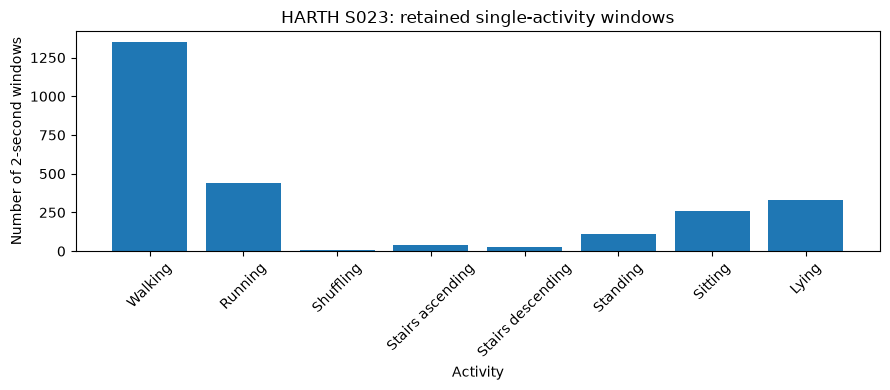

In [5]:
# =================== 05. Inspect Retained Activity Support ===================

# --------- 1. Count source labels before and after strict windowing. ---------
original_counts = data["label"].value_counts().sort_index()
window_counts = pd.Series(y_windows, name="label").value_counts().sort_index()

# ------- 2. Report original sample counts and retained window support. -------
distribution = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[int(code)] for code in original_counts.index],
    "source_samples": original_counts.to_numpy(),
    "retained_windows": [
        int(window_counts.get(code, 0)) for code in original_counts.index
    ],
})
display(distribution)

# -------- 3. Visualise retained activity windows with labelled axes. ---------
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(distribution["activity"], distribution["retained_windows"])
ax.set(
    title="HARTH S023: retained single-activity windows",
    xlabel="Activity", ylabel="Number of 2-second windows",
)
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

**06. Visualise an Original Signal Window**

Plot the lower-back acceleration channels from the first retained two-second window, using the original values in **g** without filtering or scaling.

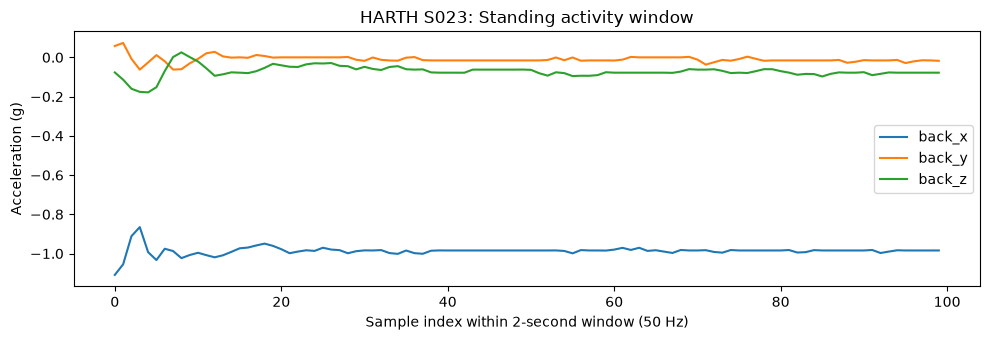

Source indices: 0 to 99
Label purity: 1.0


In [6]:
# =================== 06. Visualise Original Window Signals ===================

# ----------- 1. Require a retained source window before plotting. ------------
if len(X_windows) == 0:
    raise RuntimeError("No eligible windows; check source labels and timestamps.")

# -------- 2. Select the first retained window and its activity label. --------
first_window = 0
activity_code = int(y_windows[first_window])

# --------- 3. Plot lower-back x/y/z acceleration without rescaling. ----------
fig = plot_signal(
    X_windows[first_window, :3, :],
    title=f"HARTH S023: {ACTIVITY_NAMES[activity_code]} activity window",
    channel_names=channels[:3],
)
fig.axes[0].set_xlabel("Sample index within 2-second window (50 Hz)")
fig.axes[0].set_ylabel("Acceleration (g)")
plt.show()

# ---------- 4. Report the source row range and window label purity. ----------
print("Source indices:",
      int(window_info.iloc[first_window]["start_index"]), "to",
      int(window_info.iloc[first_window]["end_index_exclusive"]) - 1)
print("Label purity:", window_info.iloc[first_window]["label_purity"])

**07. Windowing Quality Gate**

The checks confirm tensor dimensions, source-index alignment, single-activity windows and participant identity. Overlapping windows from one participant do not support an unseen-participant performance claim.


In [7]:
# ======================== 07. Windowing Quality Gate =========================

# ------- 1. Validate channel/time tensor shape and aligned provenance. -------
assert X_windows.ndim == 3
assert X_windows.shape[1:] == (len(channels), WINDOW_SIZE)
assert len(X_windows) == len(y_windows) == len(window_info)
assert (window_info["label_purity"] == 1.0).all()
assert window_info["subject_id"].nunique() == 1

# ------- 2. Check each retained window against original source labels. -------
for row in window_info.itertuples(index=False):
    source_labels = labels[row.start_index:row.end_index_exclusive]
    assert len(source_labels) == WINDOW_SIZE
    assert (source_labels == row.label).all()

# ------- 3. Summarise passed checks and the single-participant limits. -------
print("Window shape and source-label agreement: PASSED")
print("Subject-independent validation: NOT POSSIBLE WITH ONE PARTICIPANT")
print("Feature scaling/training completed: NO")
print("Next: evaluate preprocessing/features and a full multi-subject split.")

Window shape and source-label agreement: PASSED
Subject-independent validation: NOT POSSIBLE WITH ONE PARTICIPANT
Feature scaling/training completed: NO
Next: evaluate preprocessing/features and a full multi-subject split.
